In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# New Section

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

Load the Data

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/data.csv')

In [ ]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
df.shape

(569, 33)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [ ]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [ ]:
#target variable
df.diagnosis.value_counts()

,count
diagnosis,
B,357
M,212


In [ ]:
#check for missing values
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


<Axes: >

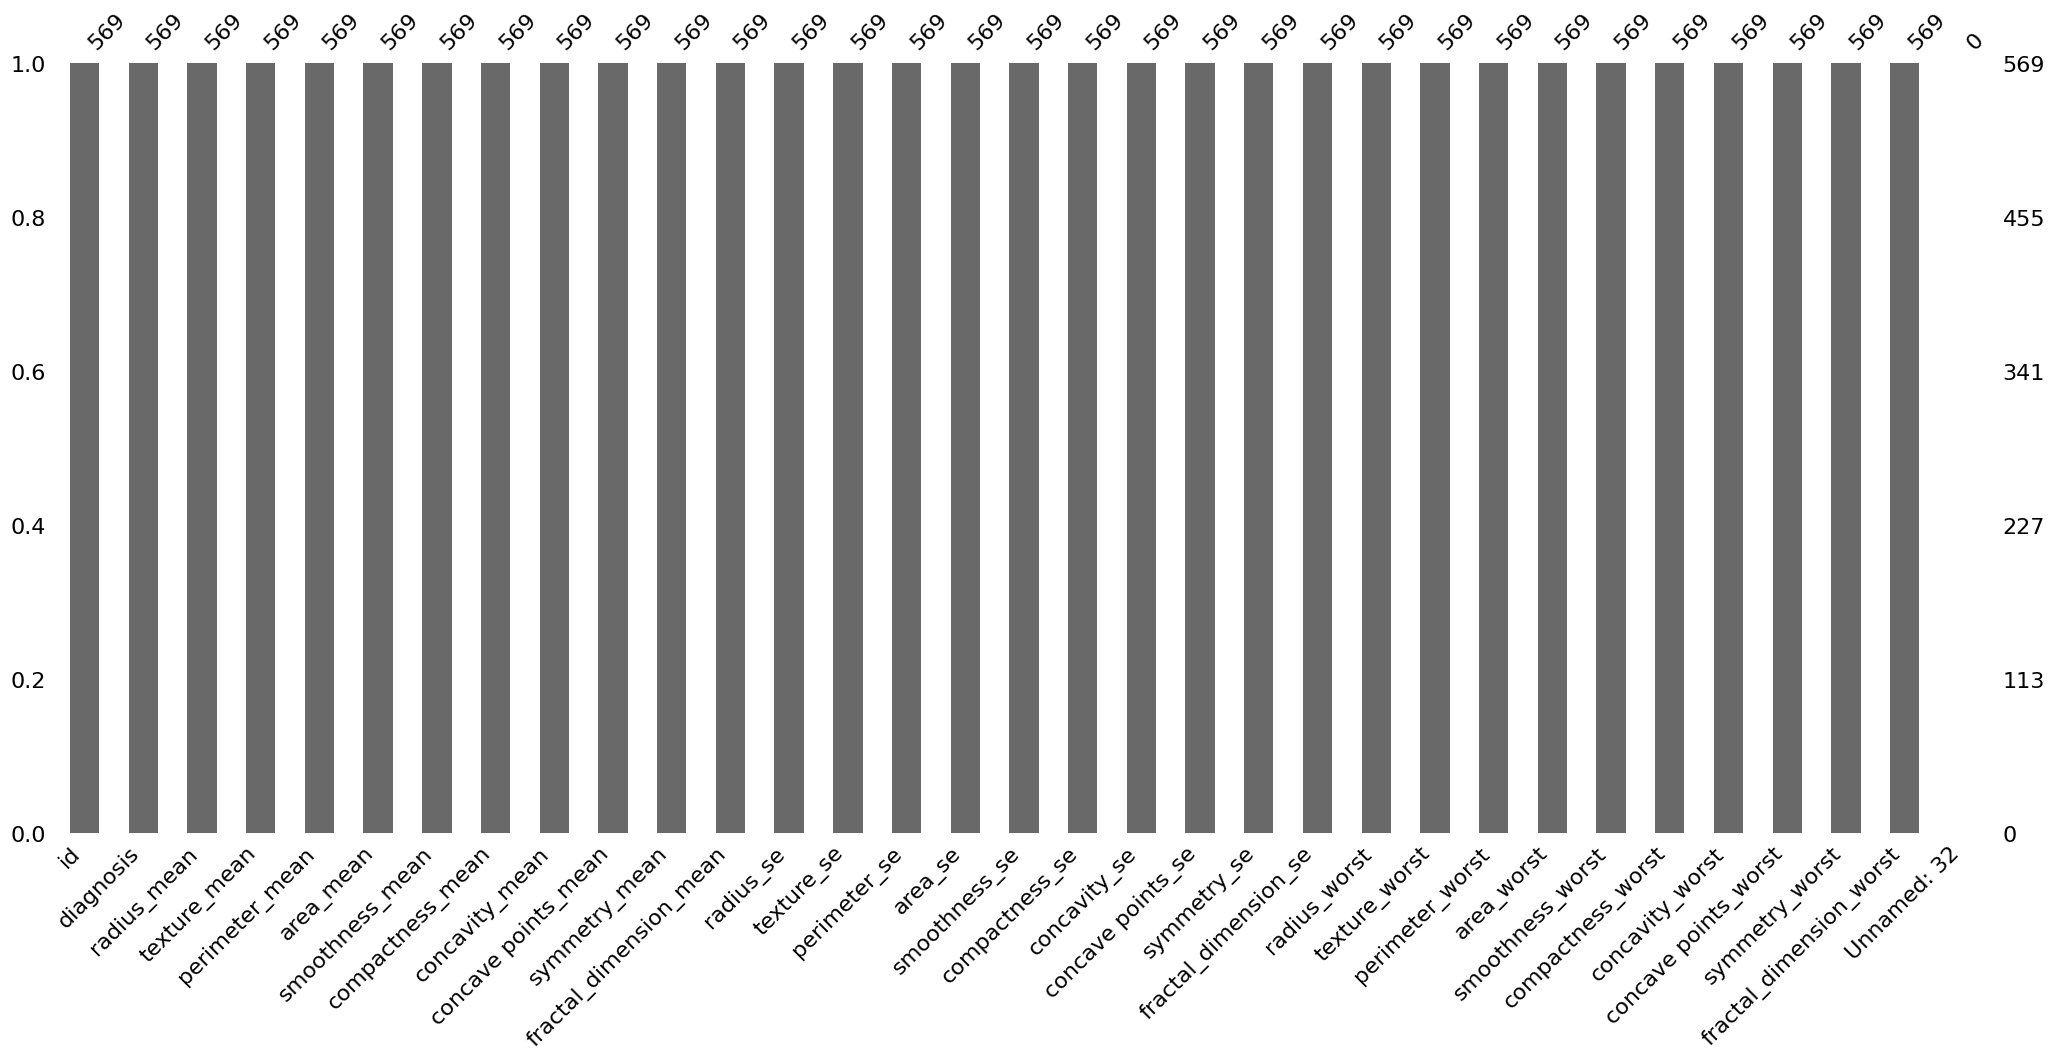

In [ ]:
#visualizing null values
import missingno as msno
msno.bar(df)

**Data Preprocessing**

In [ ]:
df.drop(['id', 'Unnamed: 32'], axis = 1, inplace = True)

In [ ]:
df['diagnosis'] = df['diagnosis'].apply(lambda val: 1 if val == 'M' else 0)

In [ ]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**EDA**

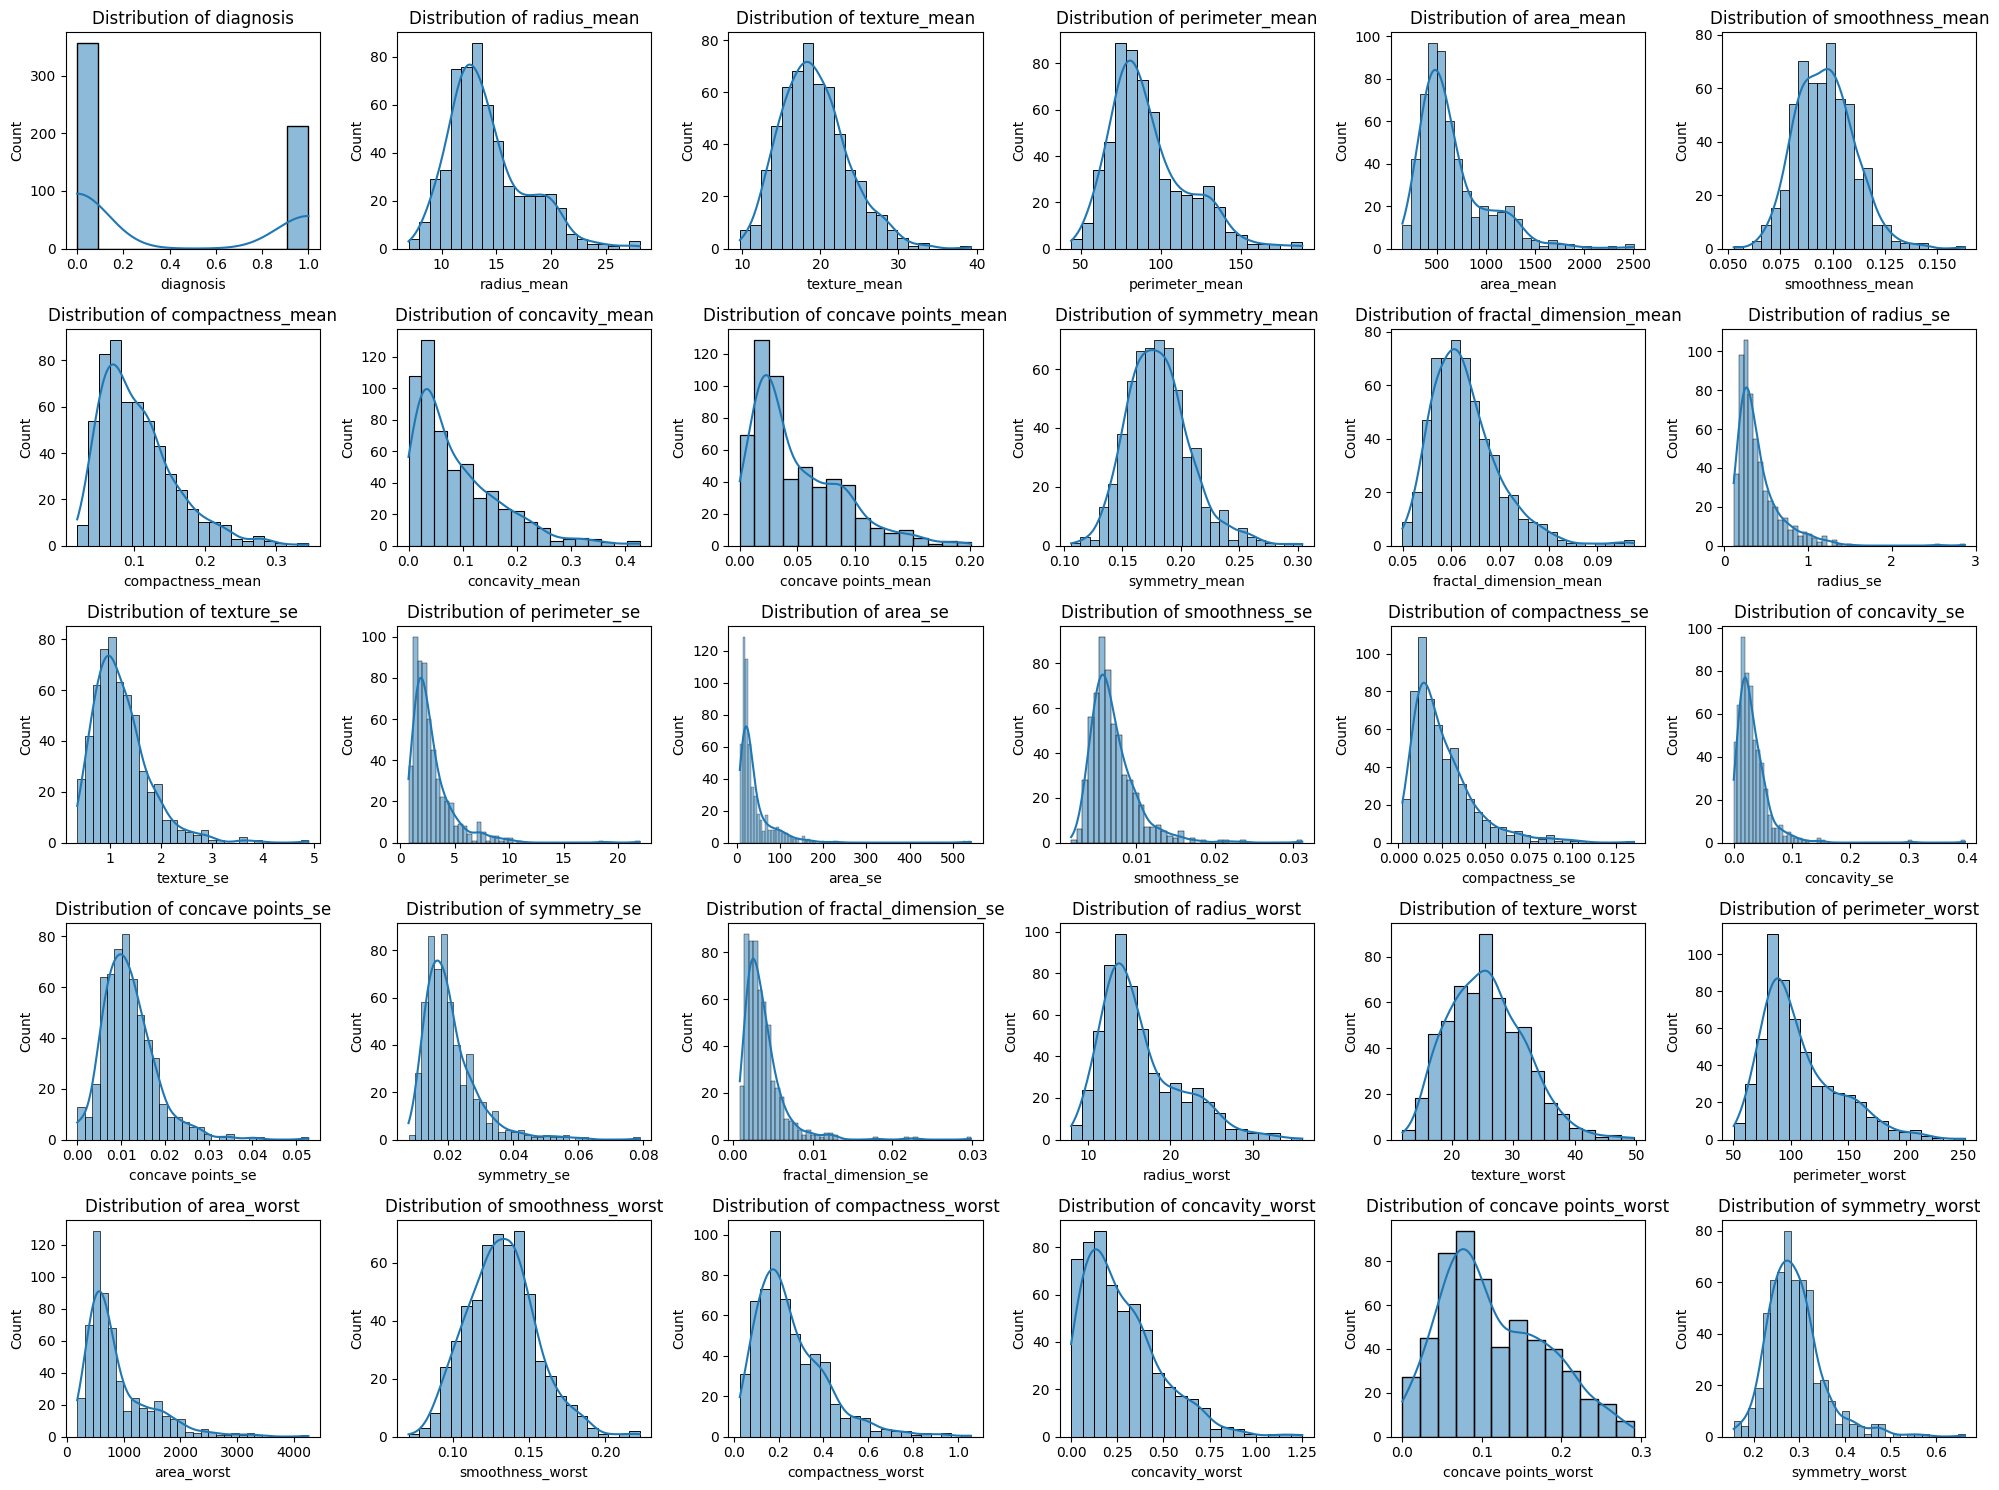

In [ ]:
#histplot
plt.figure(figsize=(20, 15))
plotnumber = 1

for column in df.columns:
    if plotnumber <= 30:
        ax = plt.subplot(5, 6, plotnumber)  # Creates a grid of 5 rows and 6 columns
        sns.histplot(df[column], kde=True)  # Use histplot with kde for density
        plt.xlabel(column)
        plt.title(f'Distribution of {column}')

    plotnumber += 1

plt.tight_layout()
plt.show()


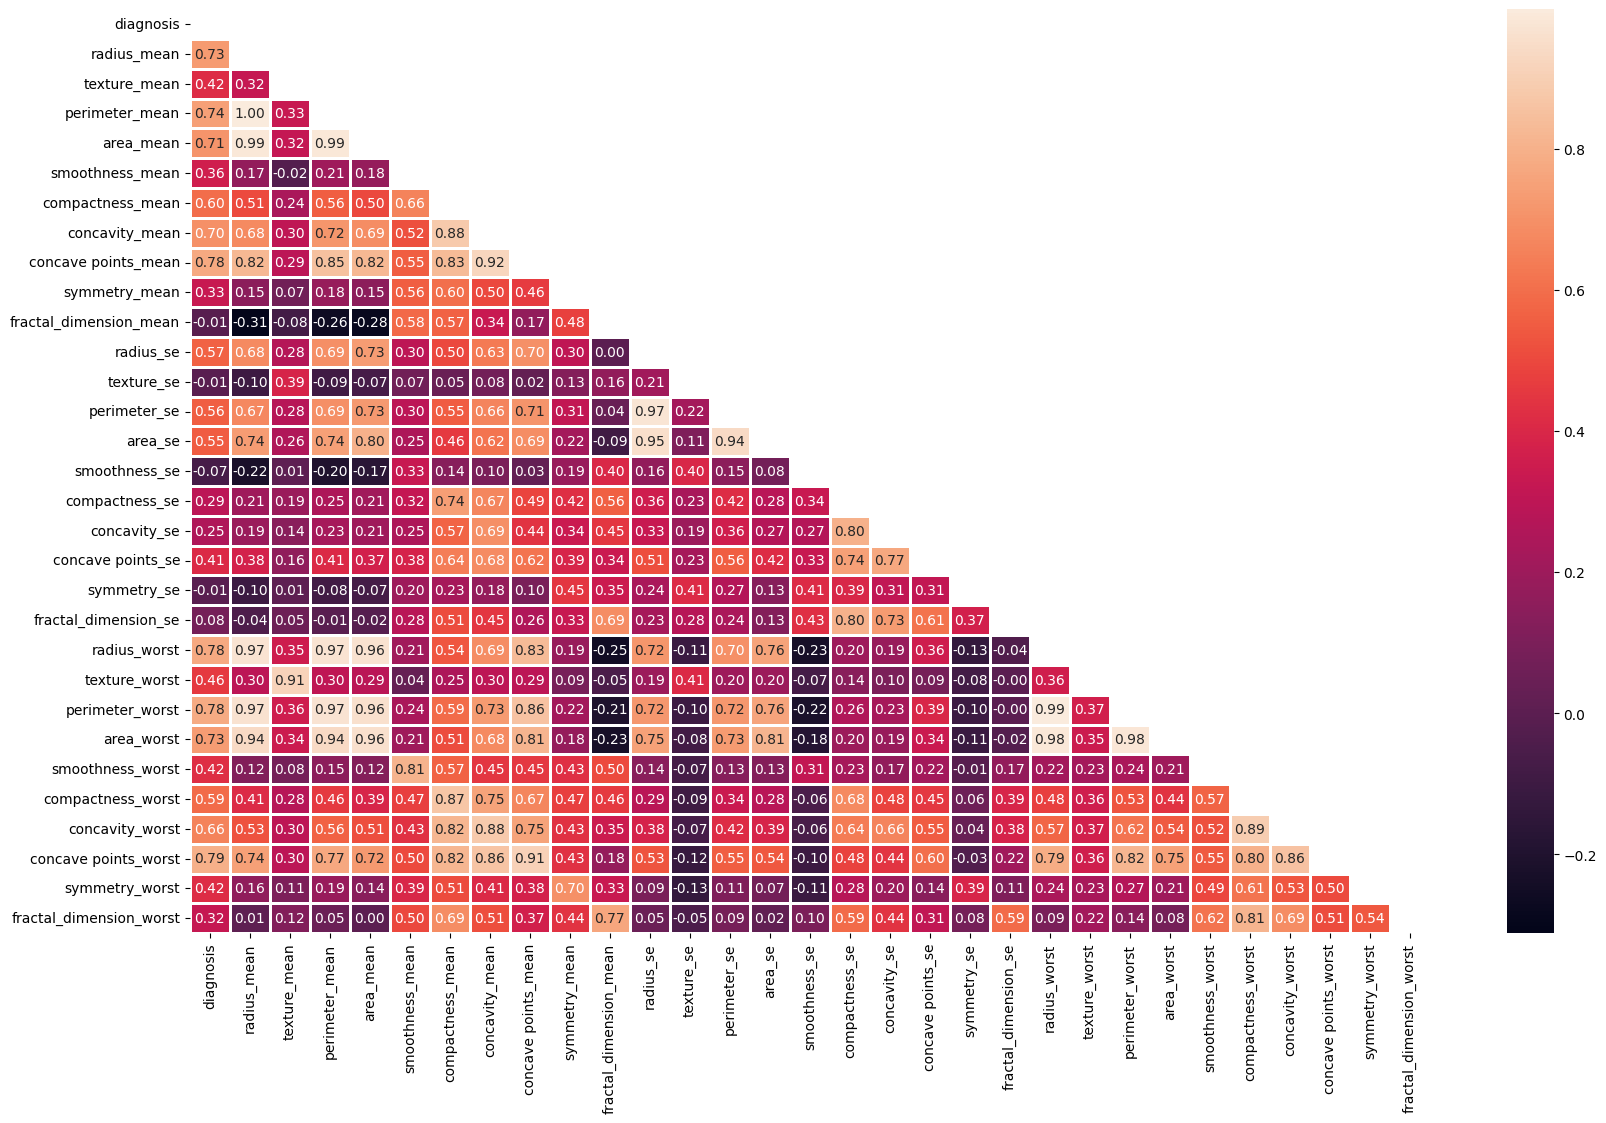

In [ ]:
#heatmap

plt.figure(figsize = (20, 12))

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype = bool))

sns.heatmap(corr, mask = mask, linewidths = 1, annot = True, fmt = ".2f")
plt.show()

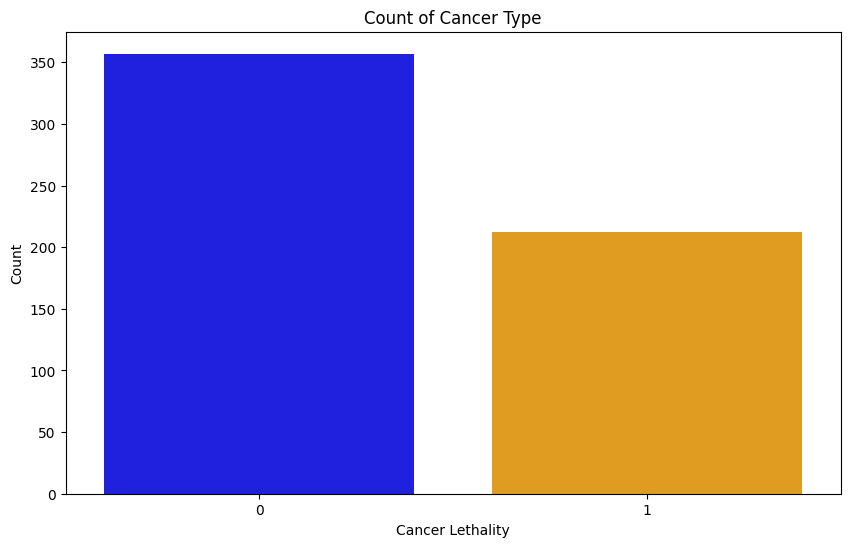

In [ ]:

plt.figure(figsize=(10, 6))

# Plotting the count of cancer types with specified palette
sns.countplot(x='diagnosis', data=df, palette={'0': 'blue', '1': 'orange'})
plt.title('Count of Cancer Type')
plt.xlabel('Cancer Lethality')
plt.ylabel('Count')

# Display the plot
plt.show()


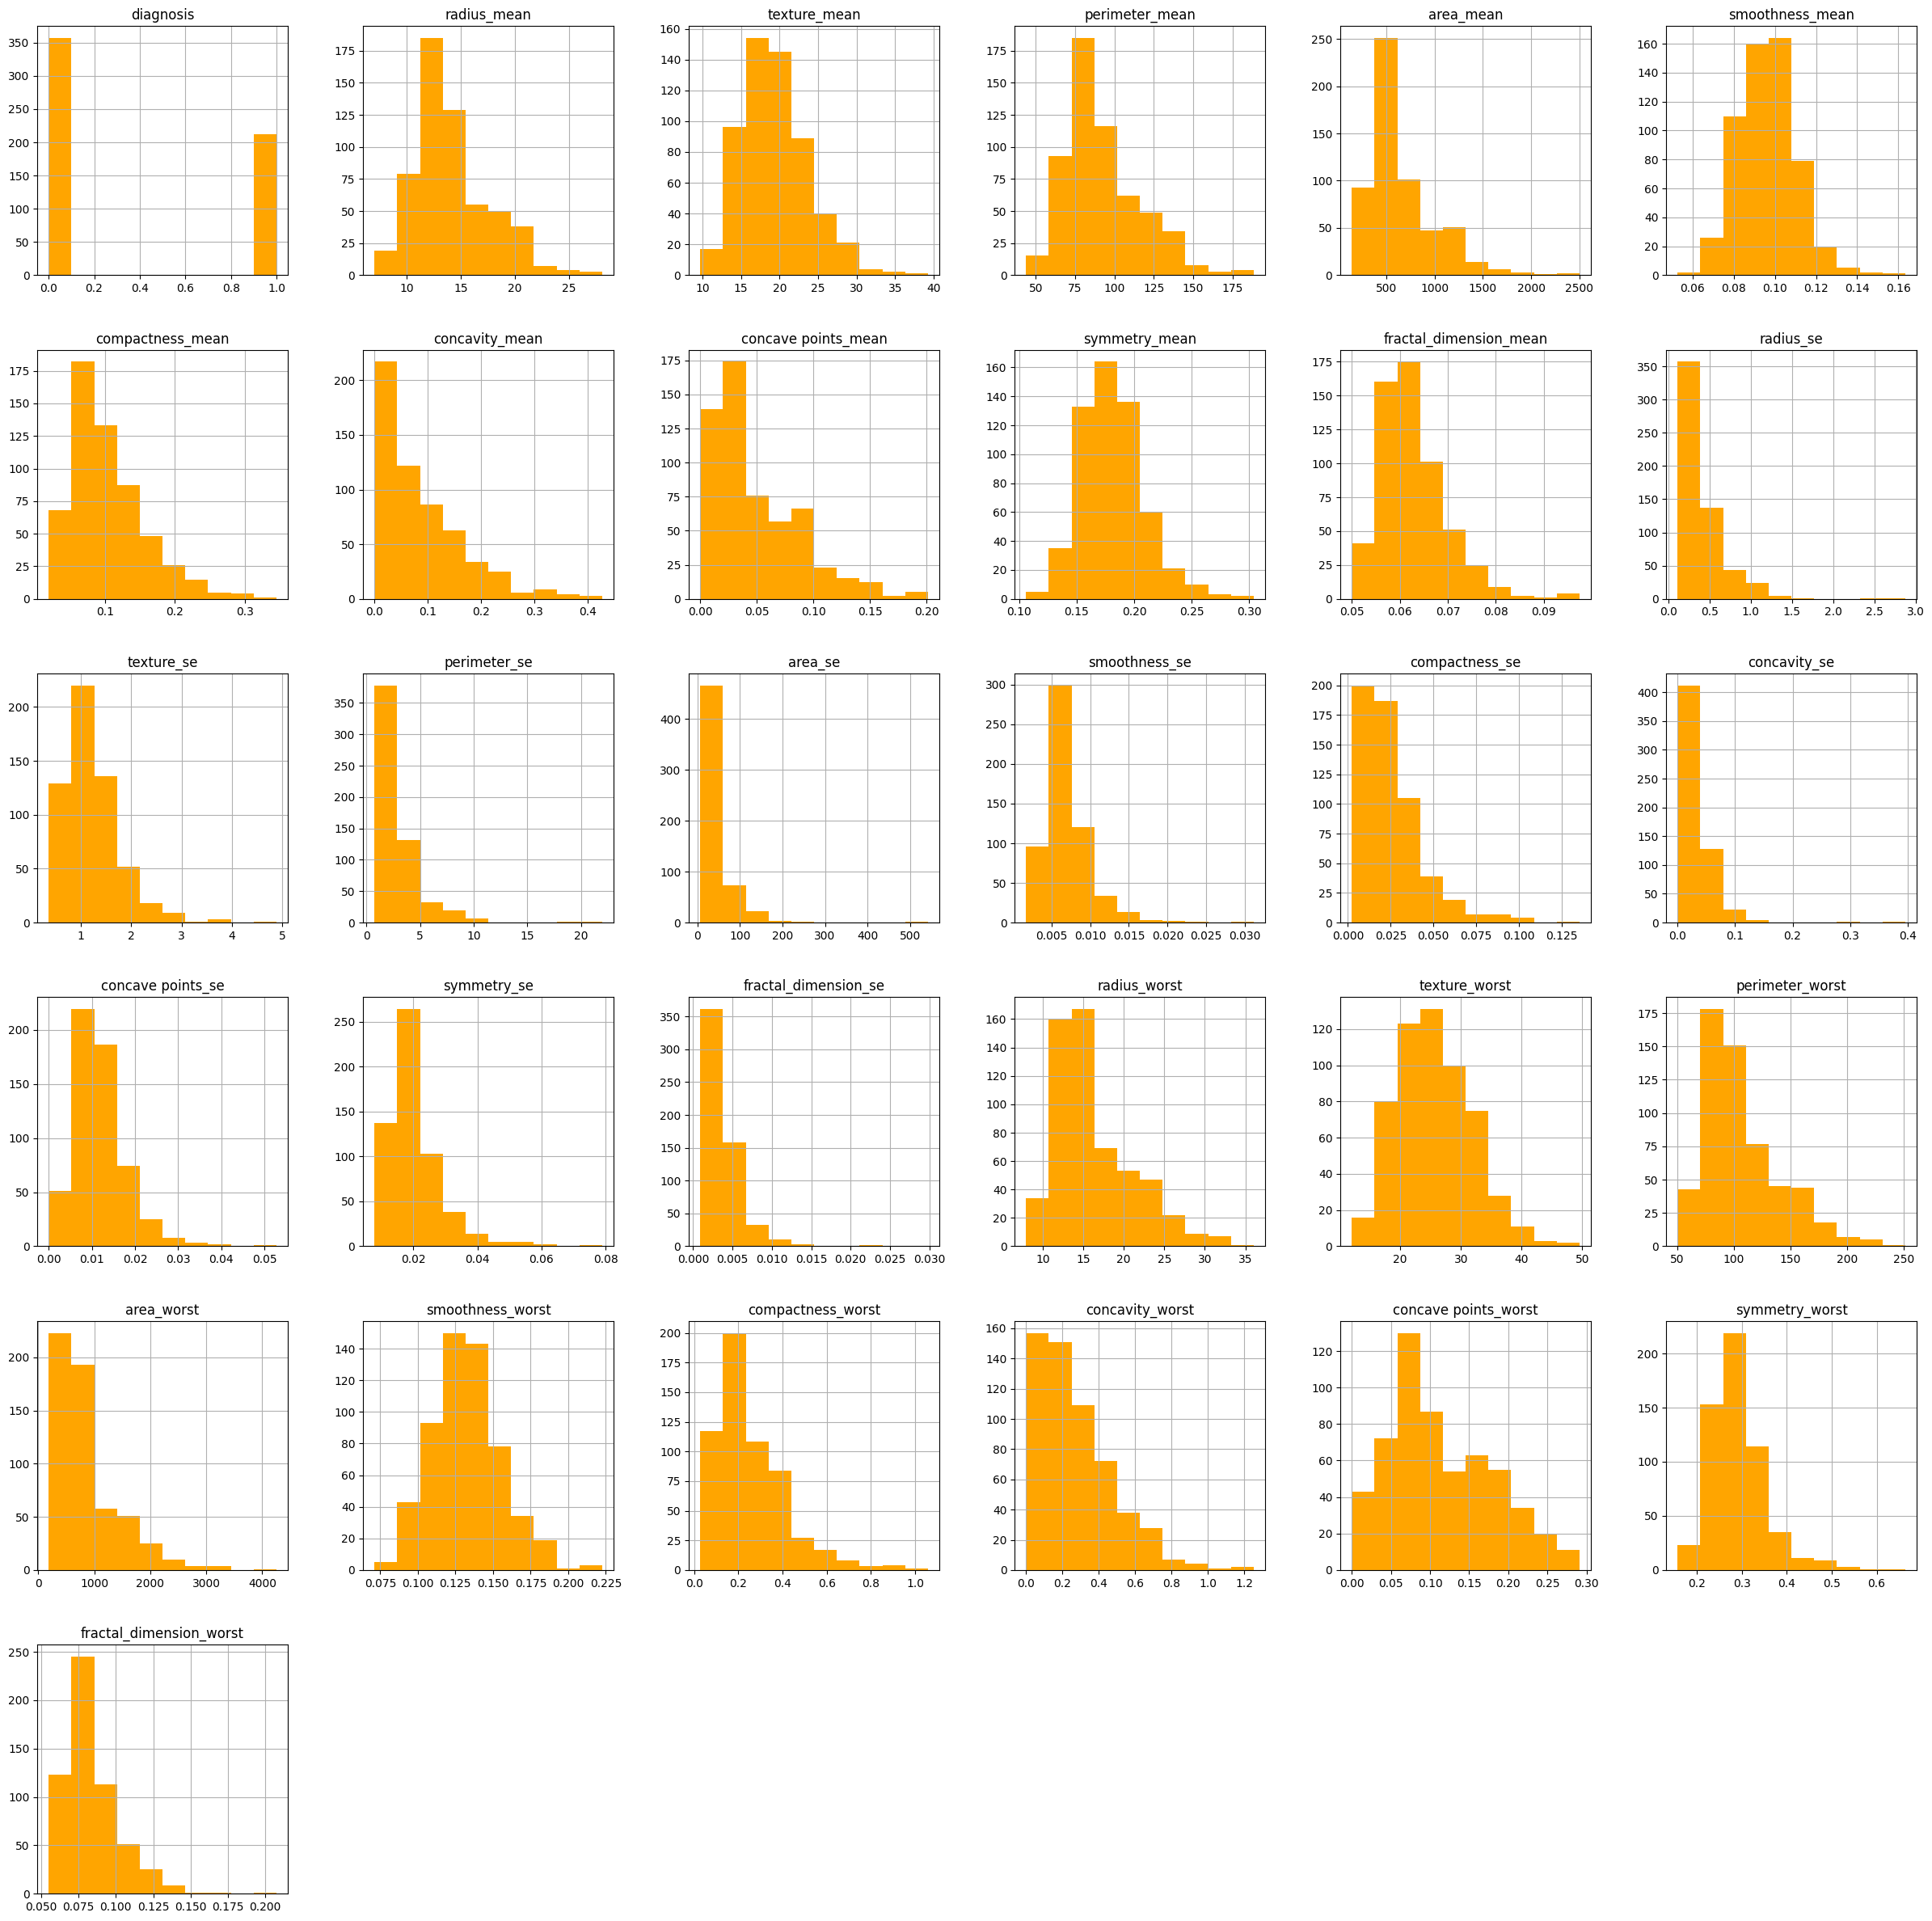

In [ ]:
#plot the histograms for each feature:
df.hist(figsize = (30,30), color = 'orange')
plt.show()

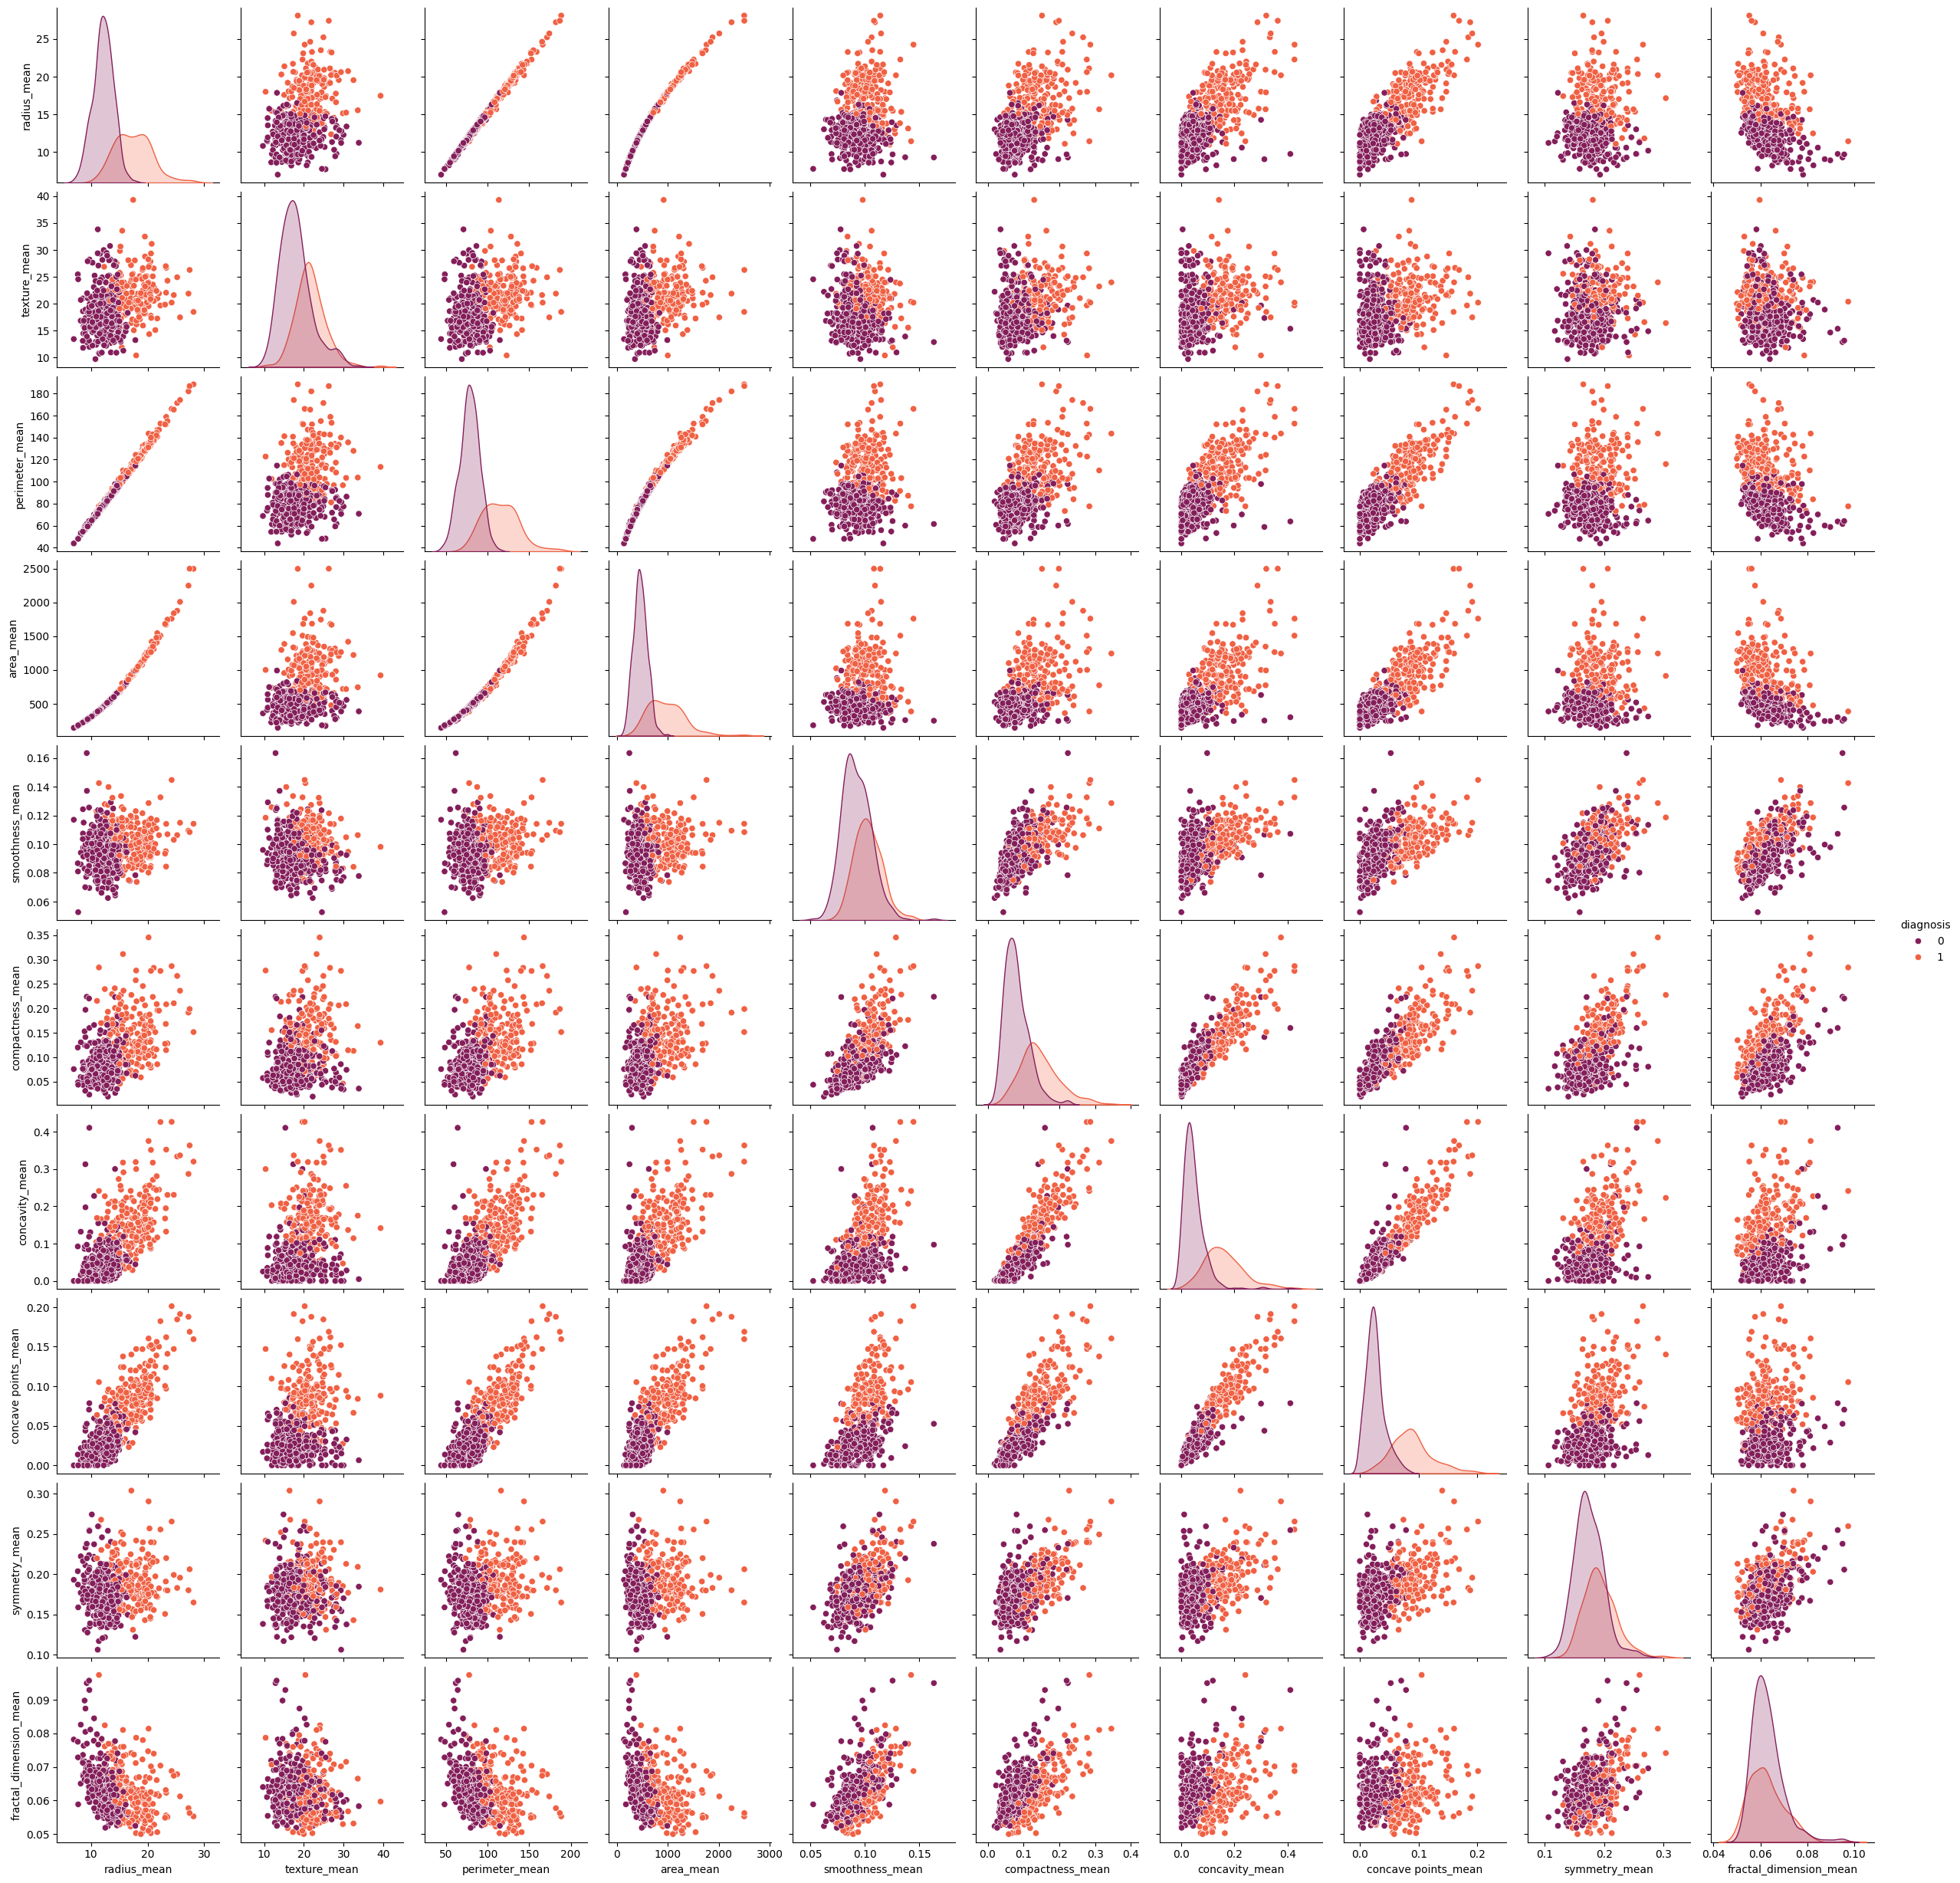

In [ ]:
#generate a scatter plot with the following columns:

columns = ['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean']

sns.pairplot(data=df[columns], hue="diagnosis", palette='rocket')

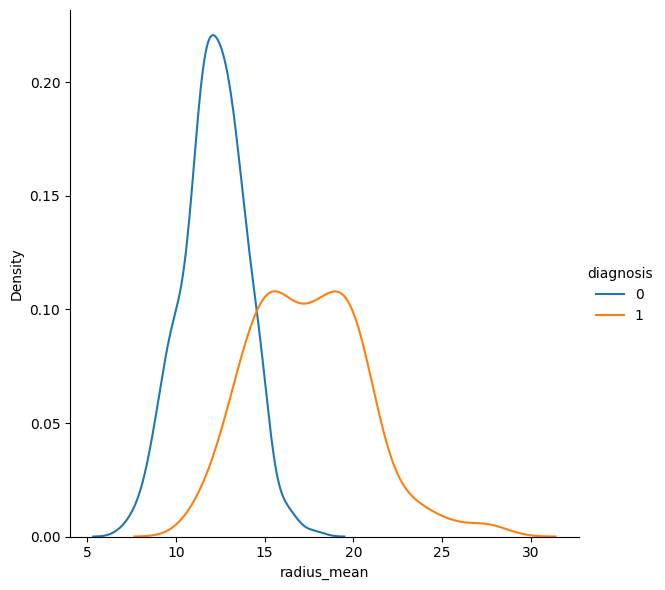

In [ ]:
# Distribution density plot KDE (kernel density estimate)
sns.FacetGrid(df, hue="diagnosis", height=6).map(sns.kdeplot, "radius_mean").add_legend()
plt.show()

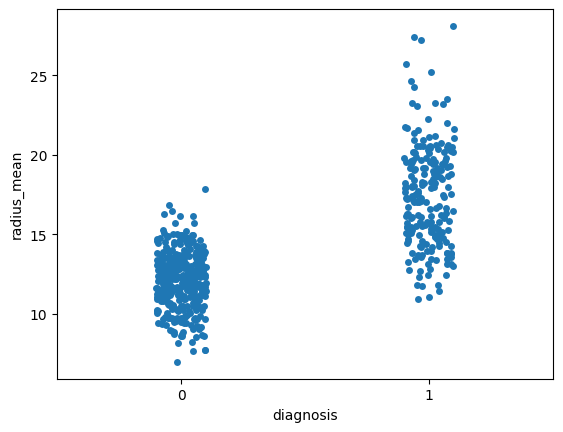

In [ ]:
# Plotting the distribution of the mean radius
sns.stripplot(x="diagnosis", y="radius_mean", data=df, jitter=True, edgecolor="gray")
plt.show()

In [ ]:
# removing highly correlated features

corr_matrix = df.corr().abs()

mask = np.triu(np.ones_like(corr_matrix, dtype = bool))
tri_df = corr_matrix.mask(mask)

to_drop = [x for x in tri_df.columns if any(tri_df[x] > 0.92)]

df = df.drop(to_drop, axis = 1)

print(f"The reduced dataframe has {df.shape[1]} columns.")

The reduced dataframe has 23 columns.


In [ ]:
df.columns

Index(['diagnosis', 'texture_mean', 'smoothness_mean', 'compactness_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'texture_se', 'area_se', 'smoothness_se', 'compactness_se',
       'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'texture_worst', 'area_worst',
       'smoothness_worst', 'compactness_worst', 'concavity_worst',
       'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

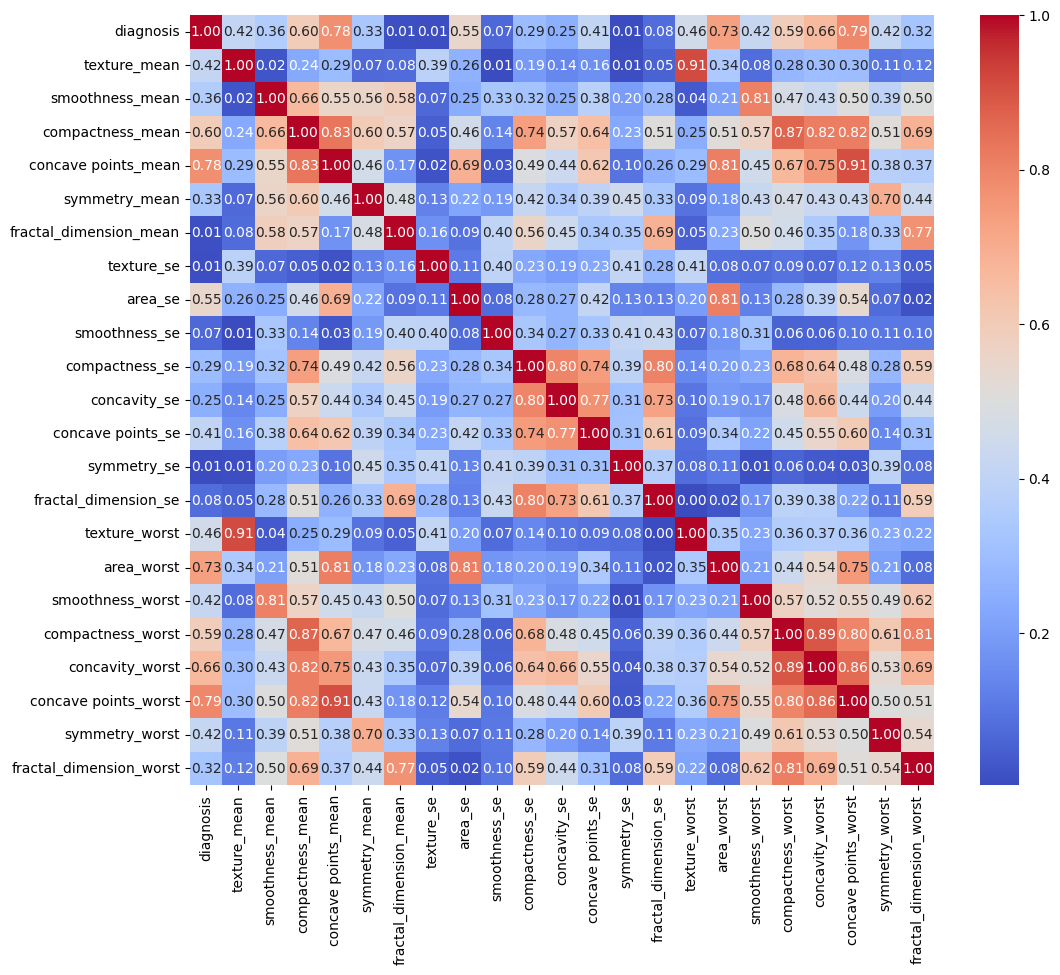

In [ ]:
# Recalculate the correlation matrix
new_corr_matrix = df.corr().abs()
plt.figure(figsize=(12, 10))
sns.heatmap(new_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()


In [ ]:
# creating features and label

X = df.drop('diagnosis', axis = 1)
y = df['diagnosis']

In [ ]:
# Splitting the data into training set and testset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 0)
print("Size of training set:", X_train.shape)
print("Size of test set:", X_test.shape)

Size of training set: (398, 22)
Size of test set: (171, 22)


**Imbalanced Dataset**
**Oversampling using SMOTE**

In [ ]:
import imblearn
from imblearn.over_sampling import SMOTE
from collections import Counter

In [ ]:
counter = Counter(y_train)
counter

Counter({0: 249, 1: 149})

In [ ]:
upsample = SMOTE()
X_train, y_train = upsample.fit_resample(X_train, y_train)
counter = Counter(y_train)
print(counter)

Counter({0: 249, 1: 249})


In [ ]:
print(f"Train Data: {X_train.shape}, {y_train.shape}")
print(f"Test Data: {X_test.shape}, {y_test.shape}")

Train Data: (498, 22), (498,)
Test Data: (171, 22), (171,)


**Scale data**

In [ ]:
# scaling data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Model**

**Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score,KFold

In [ ]:
# Initialize the model
lr = LogisticRegression(random_state=0)

# Prepare k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Perform cross-validation
cv_results = cross_val_score(lr, X_train, y_train, cv=kfold, scoring="accuracy")

# Print the cross-validation scores and their mean
print("Cross-validation scores for each fold:", cv_results)
print("Mean accuracy:", cv_results.mean())

Cross-validation scores for each fold: [0.98       1.         0.98       0.96       0.96       0.94
 1.         0.98       0.95918367 1.        ]
Mean accuracy: 0.9759183673469387


In [ ]:
#model prediction
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)




In [ ]:

acc_lr= accuracy_score(y_test, y_pred)
print(acc_lr)

0.9707602339181286


In [ ]:
# confusion matrix

print(confusion_matrix(y_test, y_pred))

[[105   3]
 [  2  61]]


In [ ]:
# classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.97      0.98       108
           1       0.95      0.97      0.96        63

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



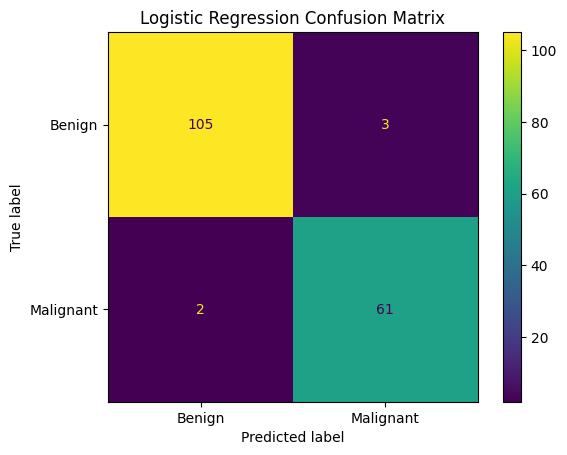

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay


# Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Benign", "Malignant"])
disp_lr.plot(cmap='viridis')
plt.title('Logistic Regression Confusion Matrix')
plt.show()


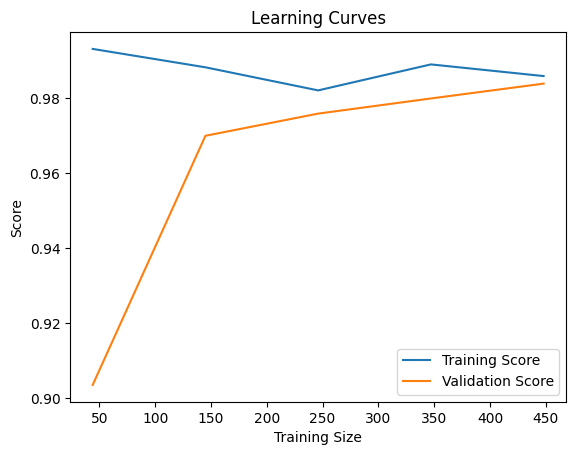

In [ ]:
from sklearn.model_selection import learning_curve

# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(lr, X_train, y_train, cv=10)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plotting
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, test_mean, label='Validation Score')
plt.title('Learning Curves')
plt.xlabel('Training Size')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, f1_score,recall_score
precision_lr = precision_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred)
recall_lr=recall_score(y_test , y_pred)

print("Precision:", precision_lr)
print("F1 Score:", f1_lr)
print("Recall:",recall_lr)

Precision: 0.953125
F1 Score: 0.9606299212598425
Recall: 0.9682539682539683


**SVC**

In [ ]:
#svc
from sklearn.svm import SVC

# Initialize the model


svm_model = SVC(random_state=42)


# Set up k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Perform cross-validation
cv_sv = cross_val_score(svm_model, X_train, y_train, cv=kfold, scoring='accuracy')

# Print results
print("Cross-Validation Accuracy Scores:", cv_sv)
print("Mean accuracy:", cv_sv.mean())


Cross-Validation Accuracy Scores: [0.96       1.         1.         0.94       0.96       0.96
 1.         1.         0.95918367 0.97959184]
Mean accuracy: 0.9758775510204082


In [ ]:
svm_model.fit(X_train, y_train)
print(accuracy_score(y_train, svm_model.predict(X_train)))
print( accuracy_score(y_test, svm_model.predict(X_test)))

0.9839357429718876
0.9649122807017544


In [ ]:
# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

svm = SVC()
parameters = {
    'gamma' : [0.0001, 0.001, 0.01, 0.1],
    'C' : [0.01, 0.5, 0.1, 1, 10, 20, 100],

}

grid_search = GridSearchCV(svm, parameters,cv=10, scoring='accuracy',verbose=3)
grid_search.fit(X_train, y_train)

Fitting 10 folds for each of 28 candidates, totalling 280 fits
[CV 1/10] END .............C=0.01, gamma=0.0001;, score=0.780 total time=   0.0s
[CV 2/10] END .............C=0.01, gamma=0.0001;, score=0.840 total time=   0.0s
[CV 3/10] END .............C=0.01, gamma=0.0001;, score=0.840 total time=   0.0s
[CV 4/10] END .............C=0.01, gamma=0.0001;, score=0.780 total time=   0.0s
[CV 5/10] END .............C=0.01, gamma=0.0001;, score=0.860 total time=   0.0s
[CV 6/10] END .............C=0.01, gamma=0.0001;, score=0.780 total time=   0.0s
[CV 7/10] END .............C=0.01, gamma=0.0001;, score=0.840 total time=   0.0s
[CV 8/10] END .............C=0.01, gamma=0.0001;, score=0.820 total time=   0.0s
[CV 9/10] END .............C=0.01, gamma=0.0001;, score=0.490 total time=   0.0s
[CV 10/10] END ............C=0.01, gamma=0.0001;, score=0.490 total time=   0.0s
[CV 1/10] END ..............C=0.01, gamma=0.001;, score=0.800 total time=   0.0s
[CV 2/10] END ..............C=0.01, gamma=0.00

GridSearchCV(cv=10, estimator=SVC(),
             param_grid={'C': [0.01, 0.5, 0.1, 1, 10, 20, 100],
                         'gamma': [0.0001, 0.001, 0.01, 0.1]},
             scoring='accuracy', verbose=3)

In [ ]:
svc_tuned = SVC(C=100,gamma=0.001)

#  Fit the model on the scaled data
svc_tuned.fit(X_train, y_train)

SVC(C=100, gamma=0.001)

In [ ]:
y_pred_sv = svc_tuned.predict(X_test)

In [ ]:
print(accuracy_score(y_train, svc_tuned.predict(X_train)))

print( accuracy_score(y_test, y_pred_sv))


0.9899598393574297
0.9766081871345029


In [ ]:

precision_sv = precision_score(y_test, y_pred_sv)
f1_sv = f1_score(y_test, y_pred_sv)
recall_sv=recall_score(y_test , y_pred_sv)

print("Precision:", precision_sv)
print("F1 Score:", f1_sv)
print("Recall:",recall_sv)

Precision: 0.9682539682539683
F1 Score: 0.9682539682539683
Recall: 0.9682539682539683


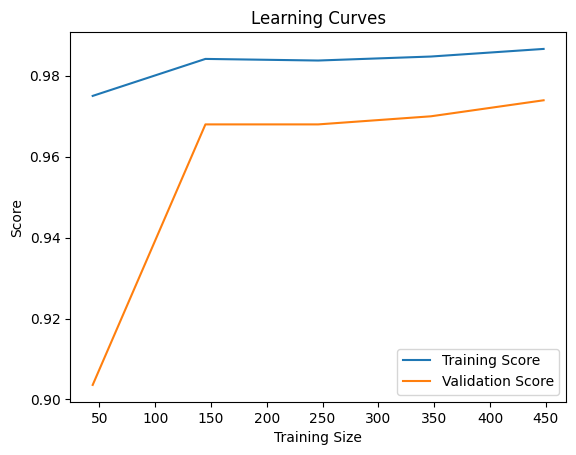

In [ ]:
from sklearn.model_selection import learning_curve

# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(svc_tuned, X_train, y_train, cv=10)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plotting
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, test_mean, label='Validation Score')
plt.title('Learning Curves')
plt.xlabel('Training Size')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
# confusion matrix

print(confusion_matrix(y_test, y_pred_sv))

[[106   2]
 [  2  61]]


In [ ]:
# classification report

print(classification_report(y_test, y_pred_sv))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       108
           1       0.97      0.97      0.97        63

    accuracy                           0.98       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



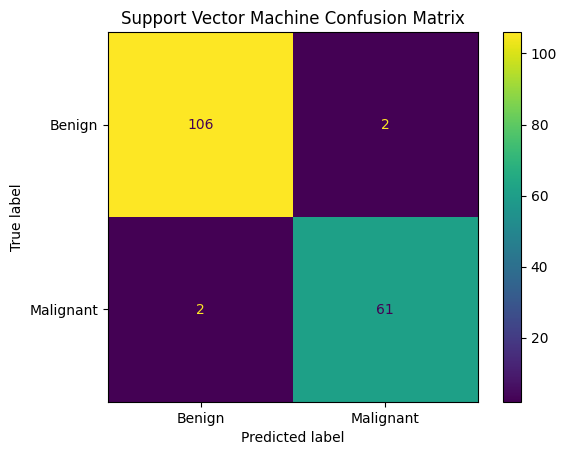

In [ ]:
# Confusion Matrix for Support Vector Machine
cm_svc = confusion_matrix(y_test, y_pred_sv)
disp_svc = ConfusionMatrixDisplay(confusion_matrix=cm_svc, display_labels=["Benign", "Malignant"])
disp_svc.plot(cmap='viridis')
plt.title('Support Vector Machine Confusion Matrix')
plt.show()

**Gradient Boosting Classifier**

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
gbc_model = GradientBoostingClassifier(random_state=42)



# Set up k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)



cv_gb = cross_val_score(gbc_model, X_train, y_train, cv=kfold, scoring='accuracy')
print("Cross-validation scores:", cv_gb)
print("Mean accuracy:", cv_gb.mean())


Cross-validation scores: [0.94       0.98       0.98       0.96       0.94       0.94
 1.         0.94       0.91836735 1.        ]
Mean accuracy: 0.9598367346938776


In [ ]:
gbc_model.fit(X_train, y_train)
print( accuracy_score(y_test, gbc_model.predict(X_test)))

0.9649122807017544


In [ ]:
#hyperparameter tuning

gbc = GradientBoostingClassifier(random_state=42)

params_gbc = {
    'loss': ['deviance', 'exponential'],
    'learning_rate': [0.001, 0.01,0.1],
    'n_estimators': [50, 100,150],  # Reduce number of trees
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]



}

grid_search_gbc = GridSearchCV(gbc, params_gbc, cv = 10, n_jobs = -1, verbose = 1,scoring='accuracy')
grid_search_gbc.fit(X_train, y_train)



Fitting 10 folds for each of 216 candidates, totalling 2160 fits


GridSearchCV(cv=10, estimator=GradientBoostingClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.001, 0.01, 0.1],
                         'loss': ['deviance', 'exponential'],
                         'max_depth': [3, 4, 5], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 150]},
             scoring='accuracy', verbose=1)

In [ ]:
grid_search_gbc.best_params_

{'learning_rate': 0.1,
 'loss': 'exponential',
 'max_depth': 3,
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'n_estimators': 100}

In [ ]:
gbc_tuned = GradientBoostingClassifier(learning_rate= 0.01,
 loss= 'exponential',
 max_depth= 4,
 min_samples_leaf= 1,
 min_samples_split= 5,
 n_estimators= 130)
gbc_tuned.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.01, loss='exponential', max_depth=4,
                           min_samples_split=5, n_estimators=130)

In [ ]:
y_pred_gbc = gbc_tuned.predict(X_test)

In [ ]:
print(accuracy_score(y_train, gbc_tuned.predict(X_train)))
acc_gbc=accuracy_score(y_test, y_pred_gbc)
print(acc_gbc)

0.9959839357429718
0.9473684210526315


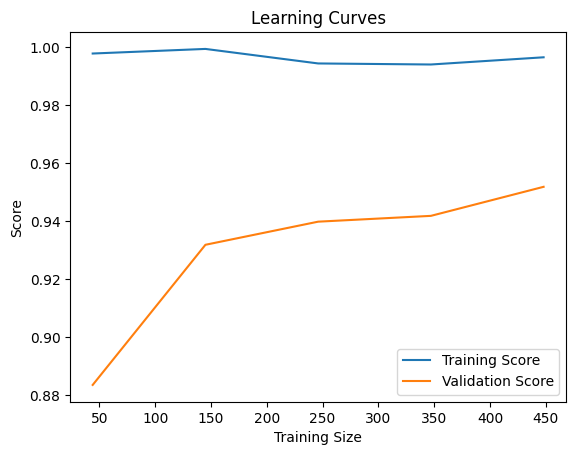

In [ ]:
# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(gbc_tuned, X_train, y_train, cv=10)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plotting
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, test_mean, label='Validation Score')
plt.title('Learning Curves')
plt.xlabel('Training Size')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
#confusion matrix
print(confusion_matrix(y_test, y_pred_gbc))

[[104   4]
 [  5  58]]


In [ ]:
# classification report

print(classification_report(y_test, y_pred_gbc))

              precision    recall  f1-score   support

           0       0.95      0.96      0.96       108
           1       0.94      0.92      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.94      0.94       171
weighted avg       0.95      0.95      0.95       171



In [ ]:
#Evaluation
precision_gbc = precision_score(y_test, y_pred_gbc)
f1_gbc = f1_score(y_test, y_pred_gbc)
recall_gbc=recall_score(y_test , y_pred_gbc)

print("Precision:", precision_gbc)
print("F1 Score:", f1_gbc)
print("Recall:",recall_gbc)

Precision: 0.9354838709677419
F1 Score: 0.928
Recall: 0.9206349206349206


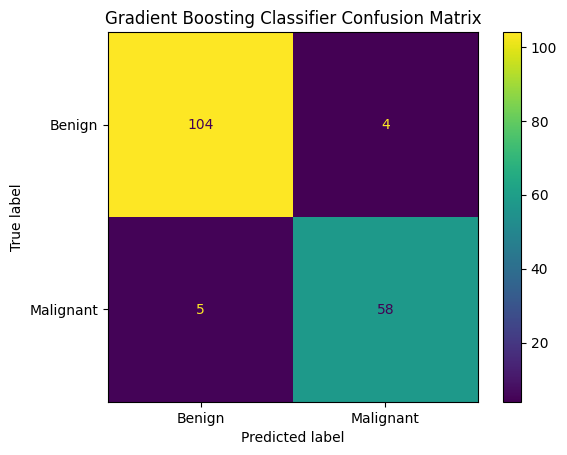

In [ ]:
# Confusion Matrix for Gradient Boosting Classifier
cm_gbc = confusion_matrix(y_test, y_pred_gbc)
disp_gbc = ConfusionMatrixDisplay(confusion_matrix=cm_gbc, display_labels=["Benign", "Malignant"])
disp_gbc.plot(cmap='viridis')
plt.title('Gradient Boosting Classifier Confusion Matrix')
plt.show()

**KNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()



# Prepare k-fold cross-validation
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Perform cross-validation
cv_knn = cross_val_score(knn, X_train, y_train, cv=kfold, scoring="accuracy")

# Print the cross-validation scores and their mean
print("Cross-validation scores for each fold:", cv_knn)
print("Mean accuracy:", cv_knn.mean())

Cross-validation scores for each fold: [0.92       0.96       0.96       0.96       0.98       0.92
 0.94       1.         0.93877551 0.95918367]
Mean accuracy: 0.953795918367347


In [ ]:
#model prediction
knn.fit(X_train, y_train)


KNeighborsClassifier()

In [ ]:
y_pred_knn = knn.predict(X_test)

In [ ]:
#accuracy score
print(accuracy_score(y_train, knn.predict(X_train)))

knn_acc = accuracy_score(y_test, y_pred_knn)
print(knn_acc)

0.9698795180722891
0.9122807017543859


In [ ]:
# confusion matrix

print(confusion_matrix(y_test, y_pred_knn))

[[100   8]
 [  7  56]]


In [ ]:
# classification report

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93       108
           1       0.88      0.89      0.88        63

    accuracy                           0.91       171
   macro avg       0.90      0.91      0.91       171
weighted avg       0.91      0.91      0.91       171



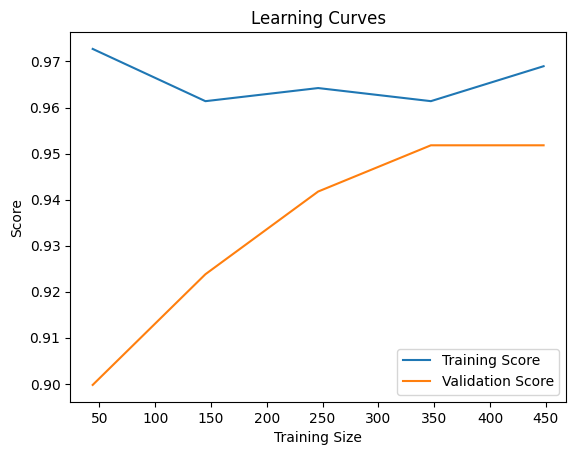

In [ ]:
# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(knn, X_train, y_train, cv=10)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plotting
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, test_mean, label='Validation Score')
plt.title('Learning Curves')
plt.xlabel('Training Size')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
k_values = list(range(1, 25,2))
accuracy_list = []
best_accuracy = 0
best_k = 0

In [ ]:
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred_k = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred_k)
    accuracy_list.append(accuracy)

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k

In [ ]:
model = KNeighborsClassifier(n_neighbors=best_k)

In [ ]:
model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_predk = model.predict(X_test)
accuracy_knn=accuracy_score(y_test , y_predk)
print(accuracy_knn)

0.9298245614035088


In [ ]:
# confusion matrix

print(confusion_matrix(y_test, y_predk))

[[102   6]
 [  6  57]]


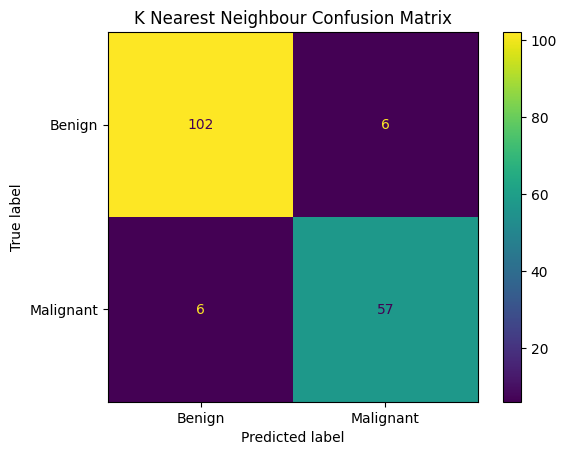

In [ ]:
# Confusion Matrix for KNN
cm_knn = confusion_matrix(y_test, y_predk)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=["Benign", "Malignant"])
disp_knn.plot(cmap='viridis')
plt.title('K Nearest Neighbour Confusion Matrix')
plt.show()

In [ ]:
#Evaluation
precision_knn = precision_score(y_test, y_predk)
f1_knn = f1_score(y_test, y_predk)
recall_knn=recall_score(y_test , y_predk)

print("Precision:", precision_knn)
print("F1 Score:", f1_knn)
print("Recall:",recall_knn)

Precision: 0.9047619047619048
F1 Score: 0.9047619047619048
Recall: 0.9047619047619048


In [ ]:
print(classification_report(y_test, y_predk))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94       108
           1       0.90      0.90      0.90        63

    accuracy                           0.93       171
   macro avg       0.92      0.92      0.92       171
weighted avg       0.93      0.93      0.93       171



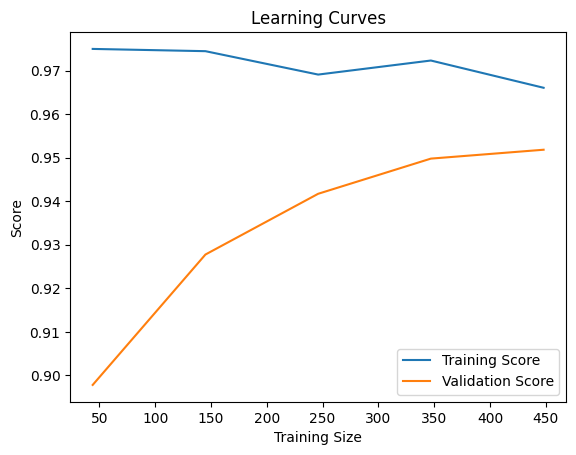

In [ ]:
# Generate learning curves
train_sizes, train_scores, test_scores = learning_curve(model, X_train, y_train, cv=10)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plotting
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, test_mean, label='Validation Score')
plt.title('Learning Curves')
plt.xlabel('Training Size')
plt.ylabel('Score')
plt.legend()
plt.show()

##Comparison of algorithms

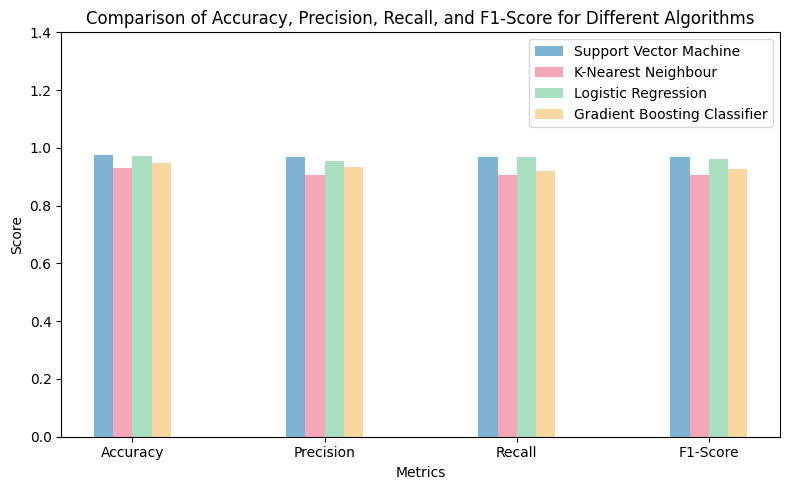

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Algorithms and metrics
algorithms = ['Support Vector Machine', 'K-Nearest Neighbour', 'Logistic Regression', 'Gradient Boosting Classifier']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']



values = {
    'Support Vector Machine': [0.9766,0.9682,0.9682,0.9682],
    'K-Nearest Neighbour': [0.9298,0.9047,0.9047,0.9047],
    'Logistic Regression': [0.9707,0.9531,0.9682,0.9606],
    'Gradient Boosting Classifier': [0.9473,0.9354,0.9206,0.9280]
}

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 5))

# Set bar width and the positions of bars
bar_width = 0.1
index = np.arange(len(metrics))  # X locations for the groups

colors=['#7FB3D5', '#F5A7B8', '#A9DFBF', '#FAD7A0']

# Plotting the bars for each algorithm
for i, algorithm in enumerate(algorithms):
     bars= ax.bar(index + i * bar_width, values[algorithm], bar_width, label=algorithm , color=colors[i])



ax.set_xlabel('Metrics')
ax.set_ylabel('Score')
ax.set_title('Comparison of Accuracy, Precision, Recall, and F1-Score for Different Algorithms')
ax.set_xticks(index + bar_width * 1.5)
ax.set_xticklabels(metrics)
ax.legend()


ax.set_ylim(0, 1.4)




# Display the plot
plt.tight_layout()
plt.show()


##Save and Load the model

In [ ]:
import pickle

with open('trained_model.pkl', 'wb') as file:
    pickle.dump(svc_tuned, file)

In [ ]:
with open('scaler.pkl', 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

**Load the model**

In [ ]:
with open('trained_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

with open('scaler.pkl', 'rb') as scaler_file:
    loaded_scaler = pickle.load(scaler_file)